# Activity distribution per trip — YouTube and Flickr

Exploratory analysis to assess whether latent class analysis (LCA) can be applied to identify
trip types from activity combinations, and how the results should be interpreted.

- **YouTube**: one video is assumed to be one trip; activities are aggregated per video from
  the clef activity labels (`youtube_clef_analysis.csv`).
- **Flickr**: trips are built by `flickr_trip_identification.ipynb` (24 h gap rule); per-trip
  activities come from the clef image labels attached to each trip (`flickr_trips.gpkg`).
- **LVVI3 survey** (reference): exactly one main activity per trip — no within-trip
  combinations exist, so combination-based LCA is only meaningful for the social media data.
- Activities are analyzed both at the **activity** level (taxonomy activities) and at the
  **activity category** level (the nine categories of `data/activity_categorization.csv`).

Outputs: none — analysis only.

## 1. Setup: build trip × activity and trip × category matrices

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA = "../../data"
cat = pd.read_csv(f"{DATA}/activity_categorization.csv", encoding="utf-8-sig")
act2cat = dict(zip(cat["activity"], cat["activity_category"]))
CATEGORIES = sorted(cat["activity_category"].unique())

### 1.1 YouTube (video = trip)

In [2]:
yt = pd.read_csv(f"{DATA}/YouTube/clef_labels/youtube_clef_analysis.csv")
X_yt_act = pd.crosstab(yt["video_id"], yt["activity"]).clip(upper=1)
X_yt_cat = (
    pd.crosstab(yt["video_id"], yt["activity"].map(act2cat))
    .reindex(columns=CATEGORIES, fill_value=0).clip(upper=1)
)
print(f"YouTube: {X_yt_act.shape[0]} videos, {X_yt_act.shape[1]} activities "
      f"({X_yt_cat.shape[1]} categories)")

YouTube: 3595 videos, 35 activities (9 categories)


### 1.2 Flickr (trip = photo cluster)

In [3]:
import geopandas as gpd
flickr = gpd.read_file(f"{DATA}/Flickr/flickr_trips.gpkg")
X_fl_act = pd.crosstab(flickr["trip_id"], flickr["activity"]).clip(upper=1)
X_fl_cat = (
    pd.crosstab(flickr["trip_id"], flickr["activity"].map(act2cat))
    .reindex(columns=CATEGORIES, fill_value=0).clip(upper=1)
)
print(f"Flickr: {X_fl_act.shape[0]} trips, {X_fl_act.shape[1]} activities "
      f"({X_fl_cat.shape[1]} categories)")

Flickr: 669 trips, 34 activities (9 categories)


## 2. How many activities per trip?

The key quantity for LCA: within-trip activity combinations. A trip supports combination-based
latent structure only if it contains more than one (category-level) activity.

In [4]:
def richness_summary(X_act, X_cat, name):
    n_act = X_act.sum(axis=1)
    n_cat = X_cat.sum(axis=1)
    s = pd.DataFrame({
        "activities per trip": [n_act.mean(), n_act.median(), n_act.quantile(.9), n_act.max()],
        "categories per trip": [n_cat.mean(), n_cat.median(), n_cat.quantile(.9), n_cat.max()],
    }, index=["mean", "median", "p90", "max"]).round(2)
    print(f"--- {name} ---")
    print(s)
    print(f"trips with 1 activity: {(n_act == 1).mean():.1%} | "
          f"1 category: {(n_cat == 1).mean():.1%} | "
          f">=2 categories: {(n_cat >= 2).mean():.1%} | "
          f">=3 categories: {(n_cat >= 3).mean():.1%}")
    return n_act, n_cat

n_yt_act, n_yt_cat = richness_summary(X_yt_act, X_yt_cat, "YouTube")
n_fl_act, n_fl_cat = richness_summary(X_fl_act, X_fl_cat, "Flickr")

--- YouTube ---
        activities per trip  categories per trip
mean                   3.27                 2.37
median                 3.00                 2.00
p90                    6.00                 4.00
max                   13.00                 8.00
trips with 1 activity: 20.1% | 1 category: 27.1% | >=2 categories: 72.9% | >=3 categories: 41.5%
--- Flickr ---
        activities per trip  categories per trip
mean                   2.24                 1.79
median                 2.00                 1.00
p90                    4.00                 3.00
max                   14.00                 7.00
trips with 1 activity: 43.5% | 1 category: 53.1% | >=2 categories: 46.9% | >=3 categories: 18.1%


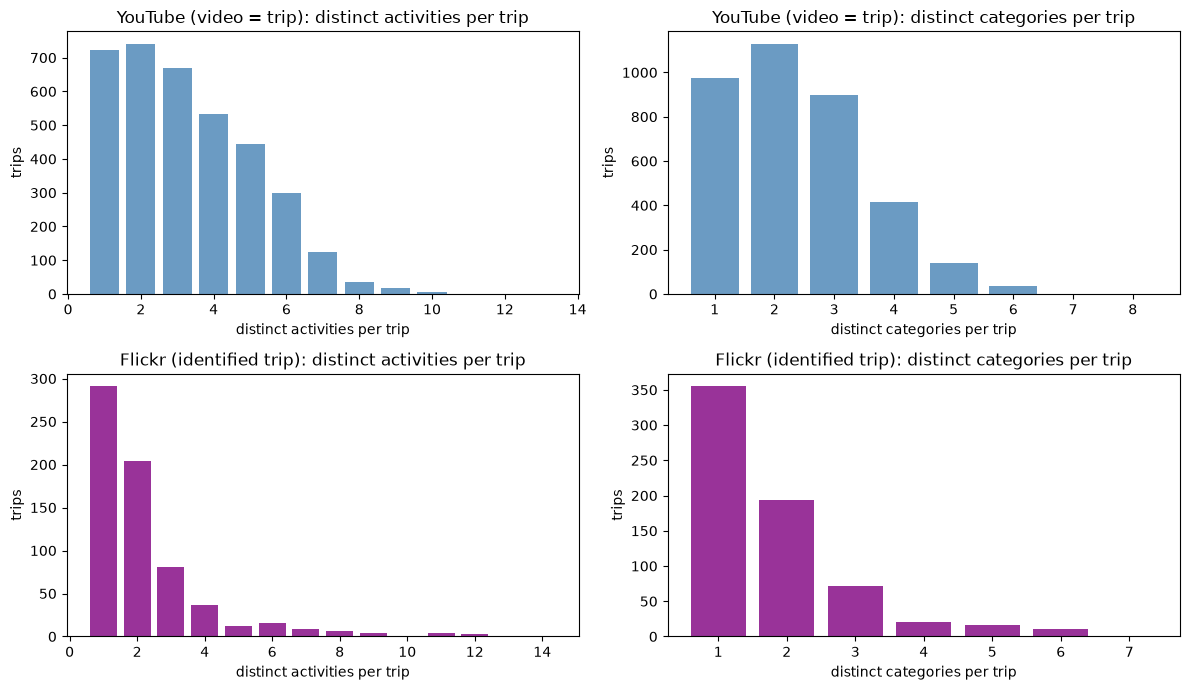

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for row, (name, n_act, n_cat) in enumerate([
        ("YouTube (video = trip)", n_yt_act, n_yt_cat),
        ("Flickr (identified trip)", n_fl_act, n_fl_cat)]):
    for col, (vals, xlabel) in enumerate([(n_act, "distinct activities per trip"),
                                          (n_cat, "distinct categories per trip")]):
        ax = axes[row, col]
        vc = vals.value_counts().sort_index()
        ax.bar(vc.index, vc.values, color="steelblue" if row == 0 else "purple", alpha=.8)
        ax.set_xlabel(xlabel)
        ax.set_ylabel("trips")
        ax.set_title(f"{name}: {xlabel}")
plt.tight_layout()
plt.show()

## 3. Activity and category prevalence

LCA indicator quality depends on endorsement rates: very rare activities add parameters and
noise; very common ones carry little class information.

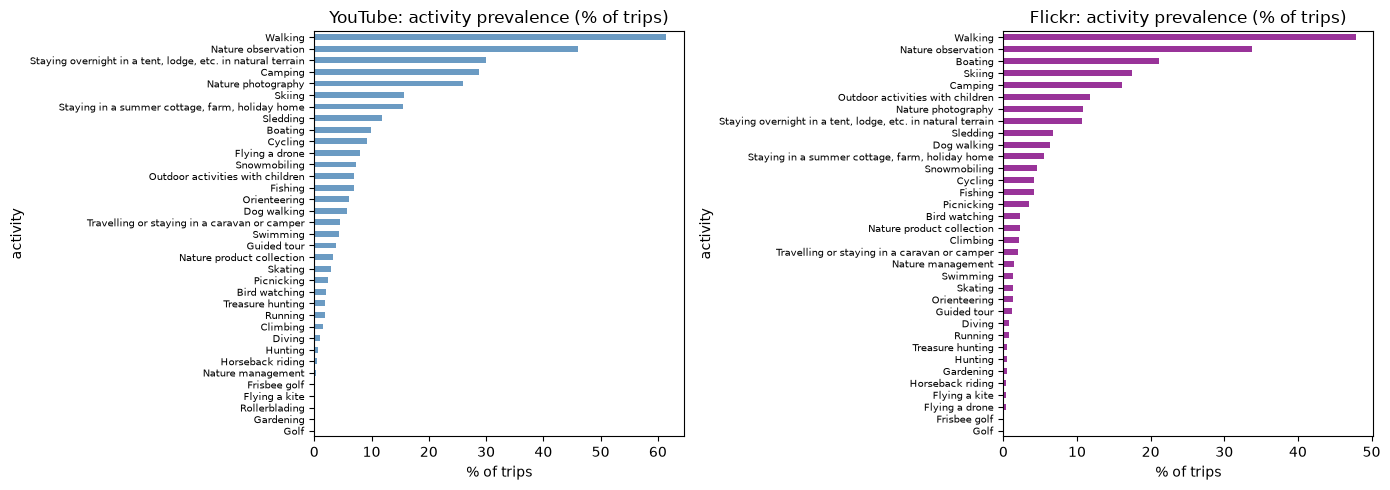

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (X, name) in zip(axes, [(X_yt_act, "YouTube"), (X_fl_act, "Flickr")]):
    prev = X.mean().sort_values() * 100
    prev.plot.barh(ax=ax, color="steelblue" if name == "YouTube" else "purple", alpha=.8)
    ax.set_xlabel("% of trips")
    ax.set_title(f"{name}: activity prevalence (% of trips)")
    ax.tick_params(axis="y", labelsize=7)
plt.tight_layout()
plt.show()

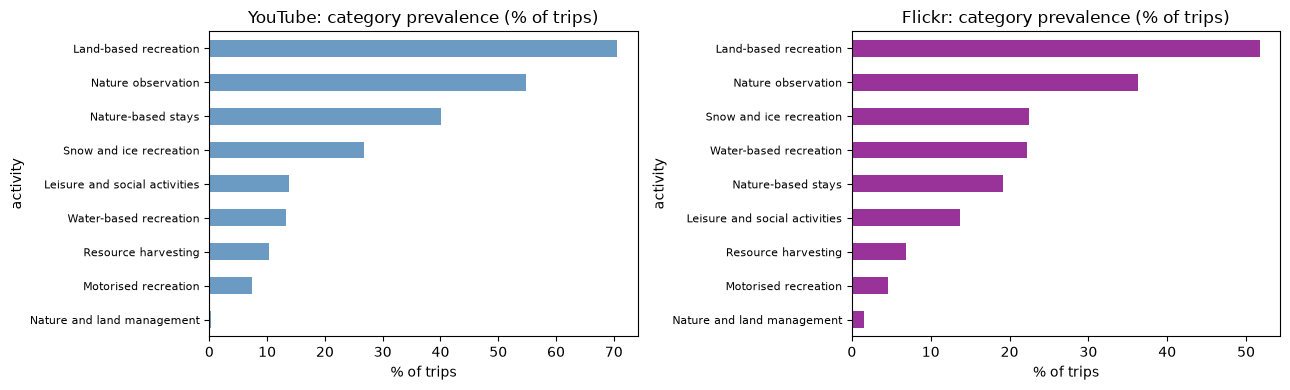

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (X, name) in zip(axes, [(X_yt_cat, "YouTube"), (X_fl_cat, "Flickr")]):
    prev = X.mean().sort_values() * 100
    prev.plot.barh(ax=ax, color="steelblue" if name == "YouTube" else "purple", alpha=.8)
    ax.set_xlabel("% of trips")
    ax.set_title(f"{name}: category prevalence (% of trips)")
    ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

In [8]:
prev_tab = pd.DataFrame({
    "YouTube": (X_yt_cat.mean() * 100).round(1),
    "Flickr": (X_fl_cat.mean() * 100).round(1),
    "LVVI3": np.nan,  # filled below for reference
})
# LVVI3 reference: one main activity per trip
df_lvvi3 = pd.read_csv(f"{DATA}/LVVI3/lvvi3_survey_en.csv")
lv_cat = df_lvvi3["activity"].map(act2cat)
prev_tab["LVVI3"] = lv_cat.value_counts(normalize=True).reindex(CATEGORIES) * 100
prev_tab.round(1)

,YouTube,Flickr,LVVI3
activity,,,
Land-based recreation,70.6,51.7,63.4
Leisure and social activities,13.8,13.8,5.1
Motorised recreation,7.3,4.6,1.3
Nature and land management,0.4,1.5,0.2
Nature observation,54.7,36.3,4.2
Nature-based stays,40.1,19.1,3.8
Resource harvesting,10.3,6.9,9.3
Snow and ice recreation,26.8,22.4,9.1
Water-based recreation,13.3,22.3,3.5


## 4. Co-occurrence within trips

Strong residual associations between indicators violate LCA's local-independence assumption —
unlike the LVVI3 survey (single activity per trip), these bivariate co-occurrences are
**observable** here and should be checked in any fitted model.

In [9]:
def cooccurrence(X, name, top_n=12):
    # most frequent category pairs (trips endorsing both)
    pairs = []
    cols = X.columns
    M = X.values
    for i in range(len(cols)):
        for j in range(i + 1, len(cols)):
            both = ((M[:, i] > 0) & (M[:, j] > 0)).sum()
            if both > 0:
                pairs.append((f"{cols[i]} + {cols[j]}", both, both / len(X)))
    pr = pd.DataFrame(pairs, columns=["pair", "n_trips", "share"]).sort_values("n_trips", ascending=False)
    print(f"--- {name}: {len(pr)} co-occurring category pairs ---")
    print(pr.head(top_n).to_string(index=False))
    return pr

pairs_yt = cooccurrence(X_yt_cat, "YouTube")
pairs_fl = cooccurrence(X_fl_cat, "Flickr")

--- YouTube: 36 co-occurring category pairs ---
                                                 pair  n_trips    share
           Land-based recreation + Nature observation     1521 0.423088
           Land-based recreation + Nature-based stays     1155 0.321280
              Nature observation + Nature-based stays      881 0.245063
      Land-based recreation + Snow and ice recreation      435 0.121001
Land-based recreation + Leisure and social activities      387 0.107650
         Nature observation + Snow and ice recreation      382 0.106259
       Land-based recreation + Water-based recreation      327 0.090960
         Nature-based stays + Snow and ice recreation      314 0.087344
          Land-based recreation + Resource harvesting      278 0.077330
          Nature-based stays + Water-based recreation      271 0.075382
   Leisure and social activities + Nature observation      246 0.068428
          Nature observation + Water-based recreation      245 0.068150
--- Flickr: 35 c

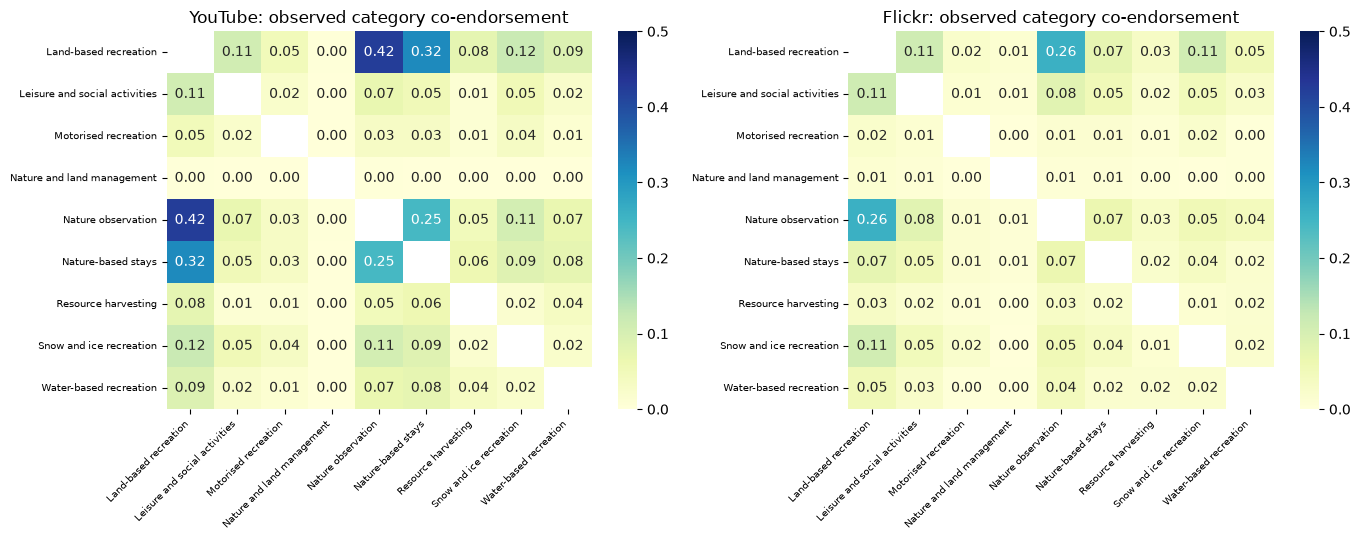

In [10]:
# observed co-endorsement matrix (categories)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, (X, name) in zip(axes, [(X_yt_cat, "YouTube"), (X_fl_cat, "Flickr")]):
    obs = (X.T.values @ X.values) / len(X)
    np.fill_diagonal(obs, np.nan)
    sns.heatmap(obs, annot=True, fmt=".2f", cmap="YlGnBu", vmin=0, vmax=0.5, ax=ax)
    ax.set_title(f"{name}: observed category co-endorsement")
    ax.set_xticklabels(CATEGORIES, rotation=45, ha="right", fontsize=7)
    ax.set_yticklabels(CATEGORIES, rotation=0, fontsize=7)
plt.tight_layout()
plt.show()

## 5. Sparsity and most frequent activity combinations

In [11]:
for name, X in [("YouTube", X_yt_act), ("Flickr", X_fl_act)]:
    print(f"--- {name} ---")
    print(f"trip x activity matrix density: {X.values.mean():.1%} "
          f"({X.values.sum()} endorsements / {X.size} cells)")
    combos = X.apply(lambda r: " + ".join(sorted(r.index[r > 0])), axis=1)
    print("unique combinations:", combos.nunique())
    print("top 10 combinations:")
    print(combos.value_counts().head(10).to_string())
    print()

--- YouTube ---
trip x activity matrix density: 9.3% (11760 endorsements / 125825 cells)
unique combinations: 1202
top 10 combinations:
Nature observation + Walking                                                                                                 195
Skiing                                                                                                                       169
Walking                                                                                                                      144
Cycling                                                                                                                      136
Nature observation + Nature photography + Walking                                                                            105
Camping + Nature observation + Staying overnight in a tent, lodge, etc. in natural terrain + Walking                          58
Camping + Nature observation + Nature photography + Staying overnight in a tent, lodge, et

## 6. Implications for LCA

Observed facts (see cells above):

1. **Combination evidence exists.** The share of trips with ≥2 observed categories is
   substantial in both sources, so a combination-based LCA is supported by the data —
   unlike LVVI3, where the single-main-activity design makes indicators structurally
   mutually exclusive.
2. **Single-activity trips remain.** Roughly a fifth (YouTube) to two fifths (Flickr) of
   trips carry only one category; these trips anchor "pure" types but carry no combination
   information. Their class assignment rests entirely on prevalence and the fitted profiles.
3. **Indicator sets.** The nine-category level gives 9 indicators (workable for LCA with a
   few hundred trips); the full activity level (30+ indicators) is sparse (density well
   below 10%) and many activities are rare — class sizes at k = 2–8 may become very uneven,
   and rare indicators mainly add noise. Filtering to activities endorsed by, e.g., ≥5% of
   trips is advisable at the activity level.
4. **Local independence can be checked.** Bivariate residuals (observed vs model-implied
   co-endorsement) are computable for these data and should be reported alongside fit
   criteria (BIC/AIC, class sizes, uncertainty, seed stability) before interpreting classes.
5. **Interpretation.** Classes will reflect *observed* activity combinations; platform
   observation bias (unphotographed activities) means unobserved ≠ absent, so class
   profiles describe what is visible in each source rather than the full activity set of a
   trip.